# 04: EDA and Feature Engineering, LGD Model

This notebook covers the exploratory data analysis and feature engineering for the LGD model features. All analysis is performed on the defaulted loans of the development sample (matured loans, see `01_data_diagnosis`). Outliers are treated and the cleaned dataframe is saved for training.

**Input:** `data/processed/checkpoint_DataFrame_for_EDA.pkl`, `data/processed/features_LGD_for_EDA.pkl`  
**Output:** `data/processed/checkpoint_df_LGD_training.pkl`, `data/processed/features_LGD_num_for_training.pkl`, `data/processed/features_LGD_cat_for_training.pkl`

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

from feature_plot import plot_boxplots_list, plot_categoricals
from feature_statistics import dataset_audit, outlier_summary
from clean_features_LGD import fit_treatment_LGD

## 1. Load Checkpoint

In [3]:
with open("data/processed/checkpoint_DataFrame_for_EDA.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]

with open("data/processed/features_LGD_for_EDA.pkl", "rb") as f:
    features_LGD = pickle.load(f)

# LGD model trains exclusively on defaulted loans of the development sample
df_LGD = df_master_features.loc[
    (df_master_features["Target_Variable_Default"] == 1) & (df_master_features["is_matured"] == 1),
    ["Target_Variable_Loss"] + features_LGD
].copy()

print(f"df_LGD shape: {df_LGD.shape}")
print(f"Features: {features_LGD}")

df_LGD shape: (100589, 17)
Features: ['interest_rate', 'loan_term_months', 'num_open_credit_lines', 'total_credit_revolving_bal', 'num_inq_in_12mths', 'tot_num_credit_lines', 'used_credit_share', 'annual_income', 'emp_length', 'earliest_cr_line_year', 'mths_since_last_delinq_LGD', 'loan_purpose', 'addr_state', 'monthly_payment', 'mths_since_recent_revol_delinq_LGD', 'dept_paym_income_ratio']


## 2. Initial Audit

In [4]:
audit_LGD = dataset_audit(df_LGD[features_LGD])
audit_LGD

,dtype,n_unique,null_count,null_pct,min,max,mean,std,skew
feature,,,,,,,,,
interest_rate,float64,529,0,0.0,5.32,28.99,14.4677,4.1196,0.3175
loan_term_months,int64,2,0,0.0,36.00,60.00,39.3274,8.2938,2.0914
num_open_credit_lines,int64,58,0,0.0,0.00,76.00,11.3956,5.2646,1.2761
total_credit_revolving_bal,int64,33733,0,0.0,0.00,1746716.00,14431.8634,19072.2346,19.6033
num_inq_in_12mths,int64,25,0,0.0,0.00,33.00,0.9396,1.2481,2.8943
tot_num_credit_lines,int64,106,0,0.0,1.00,169.00,24.1679,11.8091,0.9609
used_credit_share,float64,1119,0,0.0,0.00,182.80,57.1027,23.3890,-0.2406
annual_income,float64,9515,0,0.0,2000.00,8900060.00,65516.5627,66533.2561,66.8351
emp_length,float64,12,0,0.0,0.00,10.00,5.3712,3.7824,-0.0084


## 3. Numeric Features

### 3.1 Distribution Overview

Numeric: ['interest_rate', 'num_open_credit_lines', 'total_credit_revolving_bal', 'num_inq_in_12mths', 'tot_num_credit_lines', 'used_credit_share', 'annual_income', 'emp_length', 'earliest_cr_line_year', 'mths_since_last_delinq_LGD', 'monthly_payment', 'mths_since_recent_revol_delinq_LGD', 'dept_paym_income_ratio']
Categorical: ['loan_term_months', 'loan_purpose', 'addr_state']


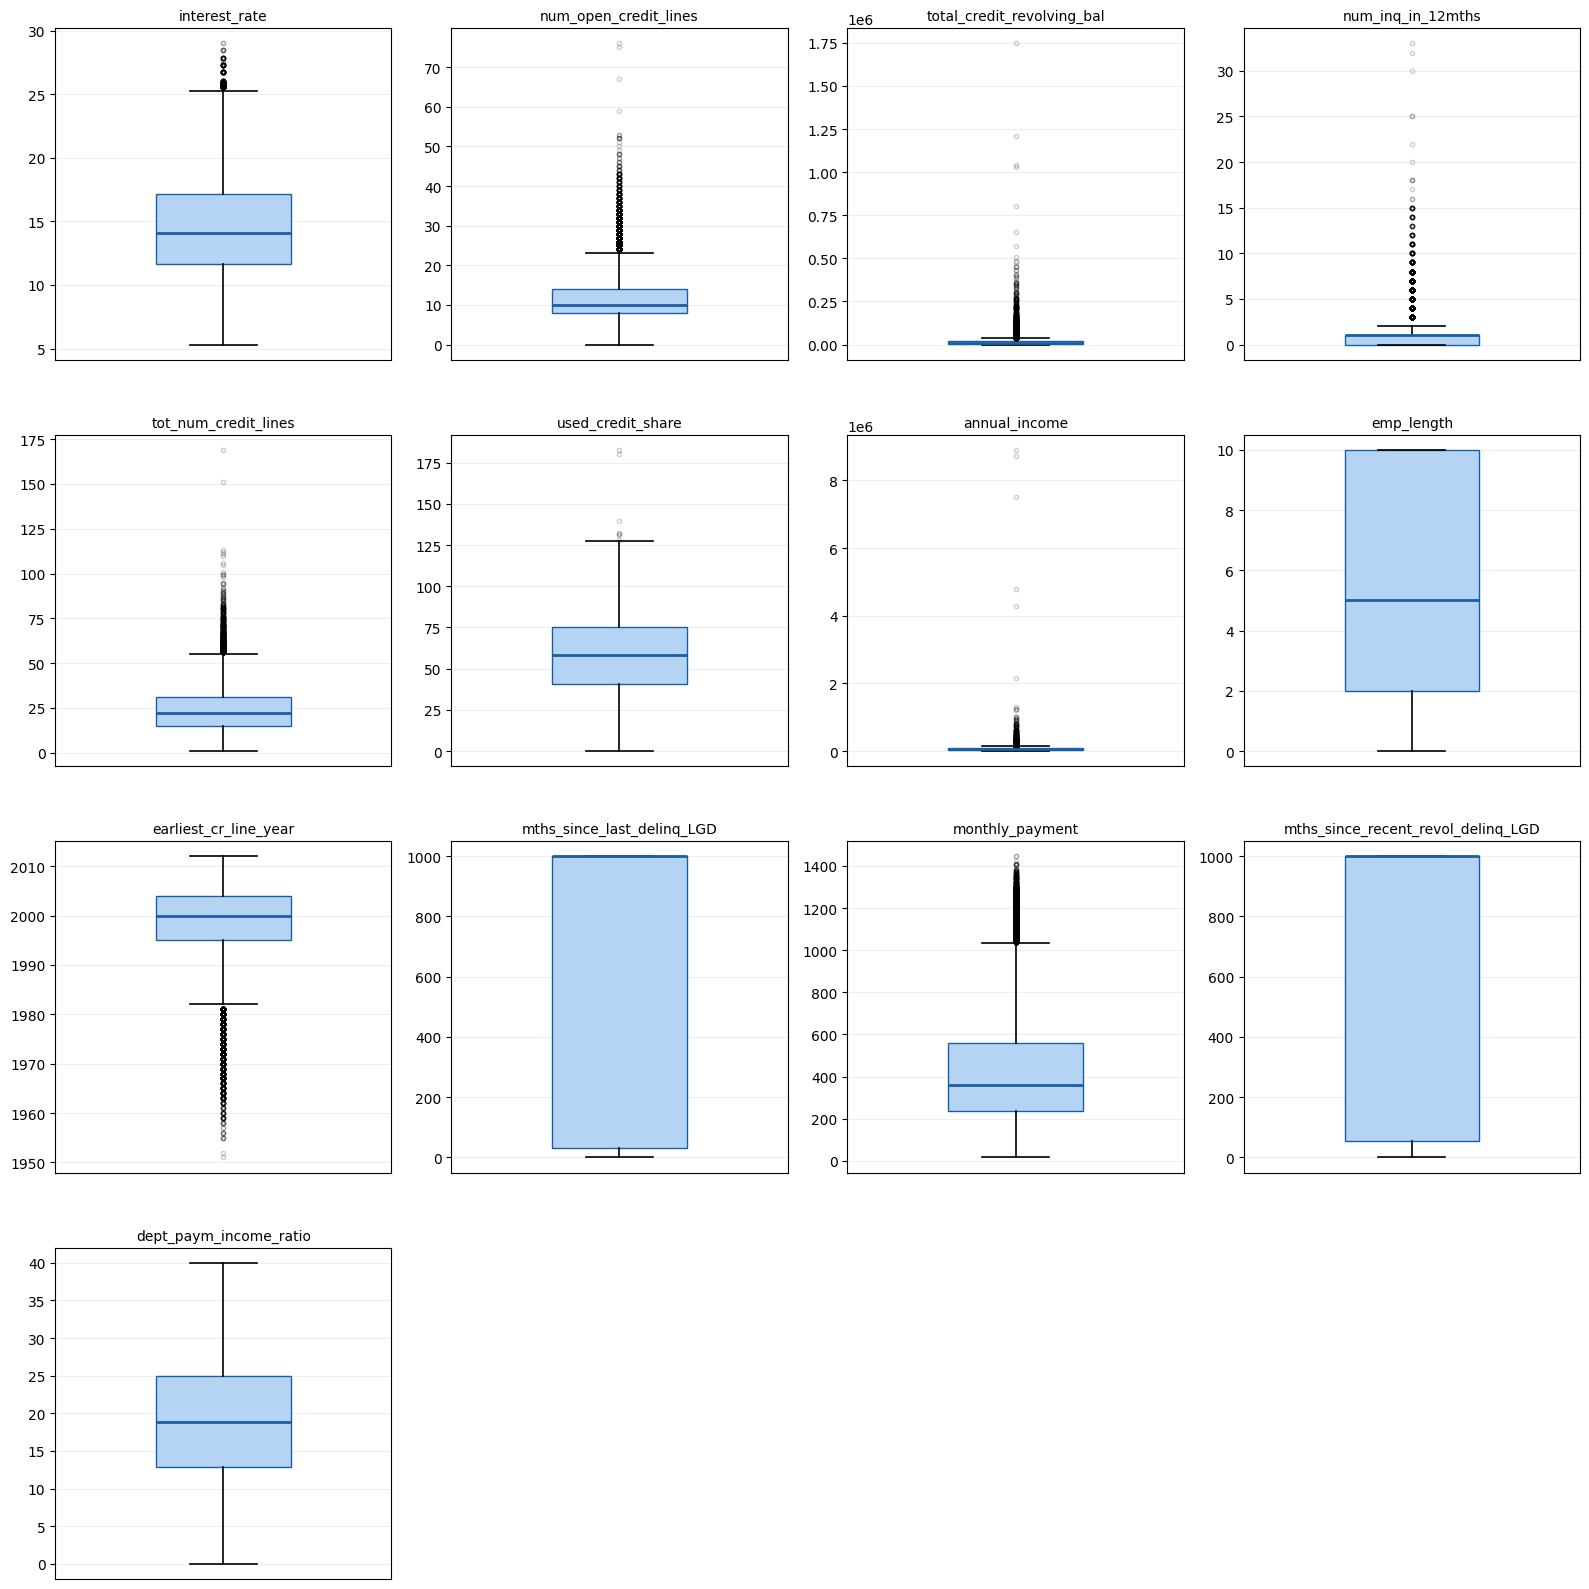

In [5]:
# Binary or categorical columns stored as numbers are one-hot encoded, not scaled
CATEGORICAL_NUMERIC = ["loan_term_months"]

num_features_LGD = [
    f for f in df_LGD[features_LGD].select_dtypes(include=[np.number]).columns
    if f not in CATEGORICAL_NUMERIC
]
cat_features_LGD = [f for f in features_LGD if f not in num_features_LGD]
print(f"Numeric: {num_features_LGD}")
print(f"Categorical: {cat_features_LGD}")

plot_boxplots_list(df_LGD, num_features_LGD, cols=4)

### 3.2 Outlier Summary

In [6]:
outlier_summary_LGD = outlier_summary(df_LGD, num_features_LGD)
outlier_summary_LGD

,Q1,Q3,IQR,lower_1.5,upper_1.5,lower_3.0,upper_3.0,moderate_n,moderate_pct,extreme_n,extreme_pct
feature,,,,,,,,,,,
interest_rate,11.67,17.14,5.47,3.46,25.35,-4.74,33.55,562,0.56,0,0.00
num_open_credit_lines,8.00,14.00,6.00,-1.00,23.00,-10.00,32.00,2902,2.89,392,0.39
total_credit_revolving_bal,5681.00,17894.00,12213.00,-12638.50,36213.50,-30958.00,54533.00,5515,5.48,1836,1.83
num_inq_in_12mths,0.00,1.00,1.00,-1.50,2.50,-3.00,4.00,10055,10.00,1578,1.57
tot_num_credit_lines,15.00,31.00,16.00,-9.00,55.00,-33.00,79.00,1710,1.70,74,0.07
used_credit_share,40.40,75.30,34.90,-11.95,127.65,-64.30,180.00,7,0.01,2,0.00
annual_income,40000.00,79000.00,39000.00,-18500.00,137500.00,-77000.00,196000.00,4892,4.86,1529,1.52
emp_length,2.00,10.00,8.00,-10.00,22.00,-22.00,34.00,0,0.00,0,0.00
earliest_cr_line_year,1995.00,2004.00,9.00,1981.50,2017.50,1968.00,2031.00,3185,3.17,304,0.30


### 3.3 Upper Tails

For every numeric feature: skewness, the share of values beyond the extreme fence (Q3 + 3 IQR), the gap between p99 and the maximum, and the skewness after log1p. These are the quantities behind the rules in `LGD_TREATMENTS`: a p99 cap where the tail is long and discontinuous (max far above p99), and no log1p where it would invert the skew (mass near zero).

In [7]:
rows = []
for f in num_features_LGD:
    s = df_LGD[f].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    fence = q3 + 3 * (q3 - q1)
    rows.append({
        "feature": f,
        "skew": s.skew(),
        "skew_log1p": np.log1p(s.clip(lower=0)).skew() if (s >= 0).all() else np.nan,
        "extreme_out_pct": (s > fence).mean() * 100,
        "p99": s.quantile(0.99),
        "max": s.max(),
        "zero_pct": (s == 0).mean() * 100,
        "nan_pct": df_LGD[f].isna().mean() * 100,
    })
tails_LGD = pd.DataFrame(rows).set_index("feature").round(3)
tails_LGD

,skew,skew_log1p,extreme_out_pct,p99,max,zero_pct,nan_pct
feature,,,,,,,
interest_rate,0.318,-0.405,0.000,24.830,28.99,0.000,0.0
num_open_credit_lines,1.276,-0.159,0.390,28.000,76.00,0.003,0.0
total_credit_revolving_bal,19.603,-2.738,1.825,72194.560,1746716.00,0.424,0.0
num_inq_in_12mths,2.894,0.594,1.569,5.000,33.00,46.888,0.0
tot_num_credit_lines,0.961,-0.405,0.074,60.000,169.00,0.000,0.0
used_credit_share,-0.241,-2.686,0.002,98.700,182.80,0.474,0.0
annual_income,66.835,0.204,1.520,220000.000,8900060.00,0.000,0.0
emp_length,-0.008,-0.649,0.000,10.000,10.00,7.795,0.0
earliest_cr_line_year,-1.184,-1.199,0.000,2011.000,2012.00,0.000,0.0


### 3.4 Apply Treatments

The treatment of every feature the selection can return is declared once, in `LGD_TREATMENTS` (`src/clean_features_LGD.py`), and `FeaturePipeline_LGD` reuses the same specification for portfolio scoring:

- balances with long upper tails: cap at p99, no log1p (it inverts the skew);
- income: cap at p99, then log1p if the skew is still above 2;
- utilisation ratios: economic ceiling at 100;
- counts with a discontinuous upper tail: cap at p99;
- debt-to-income: negatives set to 0; credit history start year: floor at p1;
- remaining numeric NaNs: median of the fit population.

The table below lists what was applied to the features selected in this run.

In [8]:
treatment_LGD = fit_treatment_LGD(df_LGD[features_LGD])
df_LGD_clean = df_LGD[["Target_Variable_Loss"]].join(treatment_LGD.transform(df_LGD[features_LGD]))
treatment_LGD.summary()

annual_income: skew after capping 1.7301 -> log1p not applied
Numeric features without a treatment step: ['interest_rate', 'loan_term_months', 'emp_length', 'mths_since_last_delinq_LGD', 'monthly_payment', 'mths_since_recent_revol_delinq_LGD']


,steps,cap_upper,log1p,cap_lower
feature,,,,
interest_rate,none,NaN,NaN,NaN
loan_term_months,none,NaN,NaN,NaN
num_open_credit_lines,cap_upper_quantile(0.99),28.00,NaN,NaN
total_credit_revolving_bal,cap_upper_quantile(0.99),72194.56,NaN,NaN
num_inq_in_12mths,cap_upper_quantile(0.99),5.00,NaN,NaN
tot_num_credit_lines,cap_upper_quantile(0.99),60.00,NaN,NaN
used_credit_share,cap_upper_value(100),NaN,NaN,NaN
annual_income,"cap_upper_quantile(0.99), log1p_if_skewed(2.0)",220000.00,False,NaN
emp_length,none,NaN,NaN,NaN


In [9]:
# Post-treatment audit
audit_LGD_num_clean = dataset_audit(df_LGD_clean[num_features_LGD])
audit_LGD_num_clean

,dtype,n_unique,null_count,null_pct,min,max,mean,std,skew
feature,,,,,,,,,
interest_rate,float64,529,0,0.0,5.32,28.99,14.4677,4.1196,0.3175
num_open_credit_lines,int64,29,0,0.0,0.00,28.00,11.3478,5.0635,0.9075
total_credit_revolving_bal,float64,32735,0,0.0,0.00,72194.56,13834.3266,12333.7074,2.1237
num_inq_in_12mths,int64,6,0,0.0,0.00,5.00,0.9203,1.1350,1.3914
tot_num_credit_lines,int64,60,0,0.0,1.00,60.00,24.1031,11.5591,0.7670
used_credit_share,float64,1013,0,0.0,0.00,100.00,57.0861,23.3520,-0.2511
annual_income,float64,9309,0,0.0,2000.00,220000.00,64179.5789,36354.5654,1.7301
emp_length,float64,12,0,0.0,0.00,10.00,5.3712,3.7824,-0.0084
earliest_cr_line_year,int64,39,0,0.0,1974.00,2012.00,1998.5248,7.2596,-0.9900


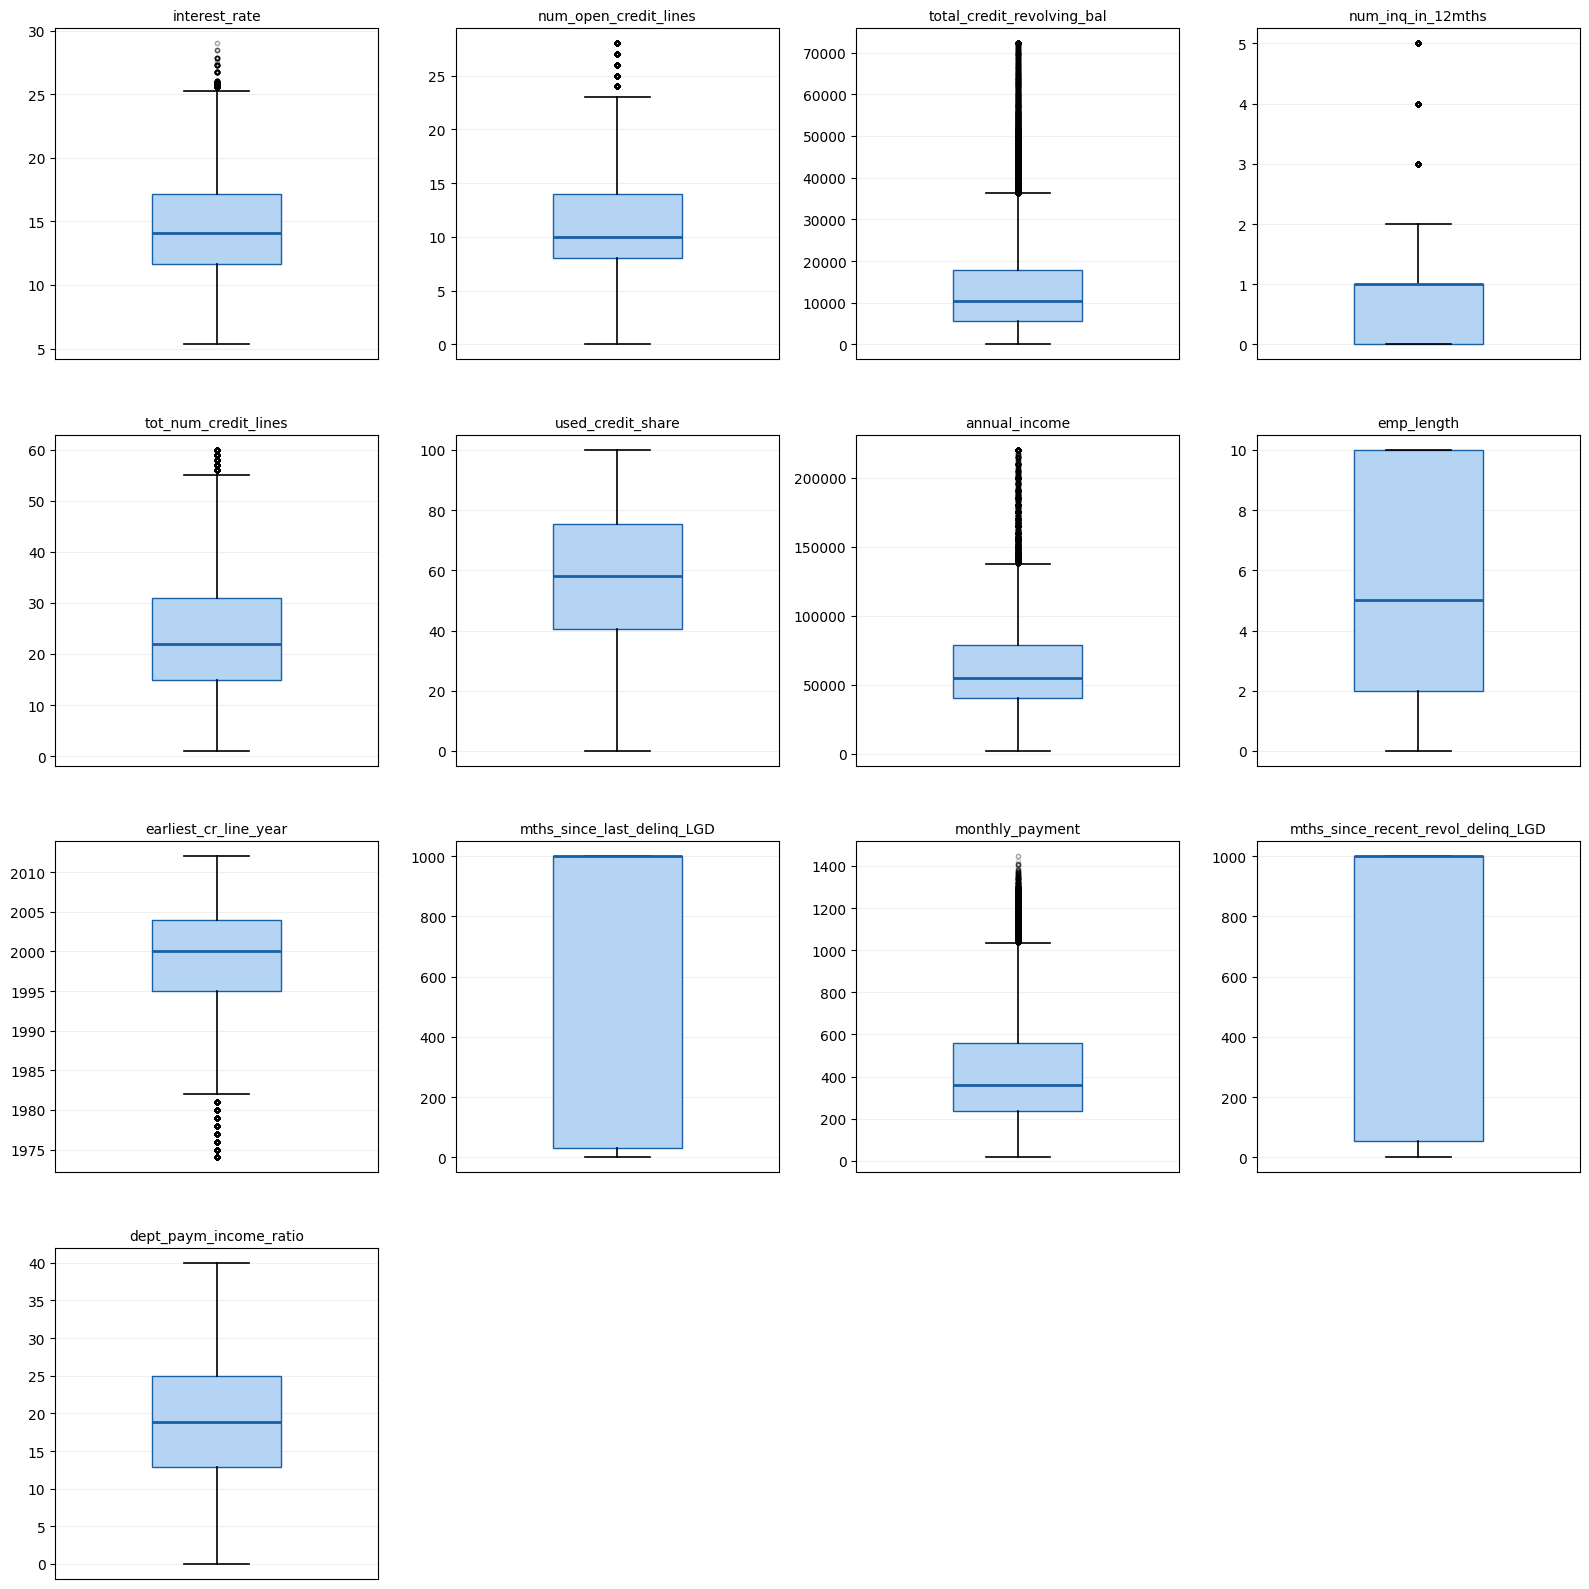

In [10]:
# Post-treatment boxplots
plot_boxplots_list(df_LGD_clean, num_features_LGD, cols=4)

In [11]:
# Post-treatment outlier summary
outlier_summary_LGD_num_clean = outlier_summary(df_LGD_clean, num_features_LGD)
outlier_summary_LGD_num_clean

,Q1,Q3,IQR,lower_1.5,upper_1.5,lower_3.0,upper_3.0,moderate_n,moderate_pct,extreme_n,extreme_pct
feature,,,,,,,,,,,
interest_rate,11.67,17.14,5.47,3.46,25.35,-4.74,33.55,562,0.56,0,0.00
num_open_credit_lines,8.00,14.00,6.00,-1.00,23.00,-10.00,32.00,2902,2.89,0,0.00
total_credit_revolving_bal,5681.00,17894.00,12213.00,-12638.50,36213.50,-30958.00,54533.00,5515,5.48,1836,1.83
num_inq_in_12mths,0.00,1.00,1.00,-1.50,2.50,-3.00,4.00,10055,10.00,1578,1.57
tot_num_credit_lines,15.00,31.00,16.00,-9.00,55.00,-33.00,79.00,1710,1.70,0,0.00
used_credit_share,40.40,75.30,34.90,-11.95,127.65,-64.30,180.00,0,0.00,0,0.00
annual_income,40000.00,79000.00,39000.00,-18500.00,137500.00,-77000.00,196000.00,4892,4.86,1529,1.52
emp_length,2.00,10.00,8.00,-10.00,22.00,-22.00,34.00,0,0.00,0,0.00
earliest_cr_line_year,1995.00,2004.00,9.00,1981.50,2017.50,1968.00,2031.00,3185,3.17,0,0.00


## 4. Categorical Features

Categorical features (text categories and `loan_term_months`) are one-hot encoded at training time. Their distribution on the defaulted development sample:

loan_term_months
36    0.8614
60    0.1386
Name: proportion, dtype: float64 

loan_purpose
debt_consolidation    0.6024
credit_card           0.1944
other                 0.0624
home_improvement      0.0516
small_business        0.0217
major_purchase        0.0186
medical               0.0127
moving                0.0094
car                   0.0093
vacation              0.0071
house                 0.0056
wedding               0.0029
renewable_energy      0.0010
educational           0.0009
Name: proportion, dtype: float64 

addr_state
CA    0.1551
NY    0.0929
FL    0.0776
TX    0.0768
NJ    0.0394
IL    0.0352
PA    0.0342
OH    0.0332
GA    0.0292
VA    0.0284
NC    0.0277
MI    0.0259
MD    0.0238
AZ    0.0235
MA    0.0212
WA    0.0187
NV    0.0178
MN    0.0175
MO    0.0171
CO    0.0170
TN    0.0152
IN    0.0151
AL    0.0140
CT    0.0134
LA    0.0130
WI    0.0115
OK    0.0105
OR    0.0102
SC    0.0094
KY    0.0093
AR    0.0088
KS    0.0069
UT    0.0065
NM    0.0060
HI    0.0053
MS

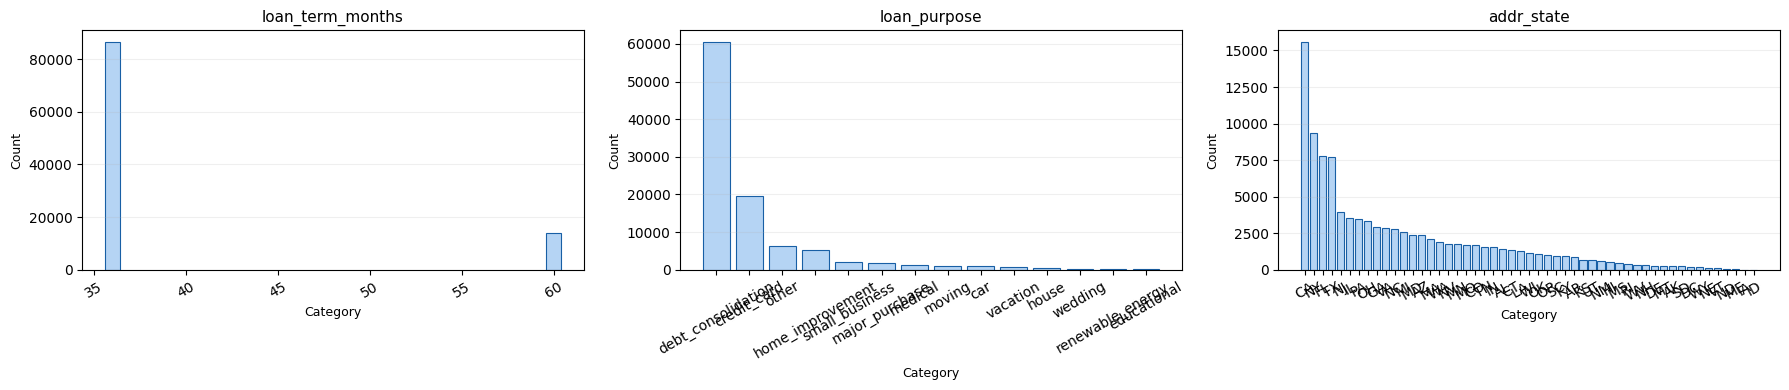

In [12]:
for col in cat_features_LGD:
    print(df_LGD_clean[col].value_counts(normalize=True).round(4), "\n")
plot_categoricals(df_LGD_clean, cat_features_LGD)

In [13]:
print(f"df_LGD_clean: {df_LGD_clean.shape}")

df_LGD_clean: (100589, 17)


## 5. Checkpoint: Save LGD Training Dataframe

In [14]:
os.makedirs("data/processed", exist_ok=True)

with open("data/processed/checkpoint_df_LGD_training.pkl", "wb") as f:
    pickle.dump({"df_LGD_clean": df_LGD_clean}, f)

with open("data/processed/features_LGD_num_for_training.pkl", "wb") as f:
    pickle.dump(num_features_LGD, f)

with open("data/processed/features_LGD_cat_for_training.pkl", "wb") as f:
    pickle.dump(cat_features_LGD, f)

print(f"Saved. Shape: {df_LGD_clean.shape}")

Saved. Shape: (100589, 17)


In [15]:
# Load checkpoint (skip re-running)
with open("data/processed/checkpoint_df_LGD_training.pkl", "rb") as f:
    data = pickle.load(f)
df_LGD_clean = data["df_LGD_clean"]

with open("data/processed/features_LGD_num_for_training.pkl", "rb") as f:
    num_features_LGD = pickle.load(f)

with open("data/processed/features_LGD_cat_for_training.pkl", "rb") as f:
    cat_features_LGD = pickle.load(f)